In [7]:
import numpy as np
from matplotlib import pyplot as plt
from IPython.display import display, HTML
import imageio

### Funkcje pomocnicze

In [76]:
DATA_PATH = "zad2_files/"

def generate_image(n, d):
    image = np.zeros(n*n)

    bp = (n * n) * d
    indicies = np.random.choice(np.arange(0, n*n), size=int(bp), replace=False)
    
    for index in indicies:
        image[index] = 1

    return image.reshape((n, n))

def save(image, name):
    np.save(f"{DATA_PATH}{name}.npy", image)

def load(name):
    return np.load(f"{DATA_PATH}{name}.npy")

def plot_image(image):
    plt.figure(figsize=(8, 8))
    plt.imshow(image, cmap='grey_r', interpolation='none')
    plt.show()

def plot_result(energy, temperature):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = len(energy)
    x = [i for i in range(epochs)]

    axes[0].plot(x, energy)
    axes[0].set_title("Wykres energii")
    axes[0].set_xlabel("Kroki")
    axes[0].set_ylabel("Energia")

    axes[1].plot(x, temperature)
    axes[1].set_title("Wykres temperatury")
    axes[1].set_xlabel("Kroki")
    axes[1].set_ylabel("Temperatura")

    plt.show()

def display_image(name):
    display(HTML(f'''
        <img src="{f"{DATA_PATH}{name}"}"
        style="width: 1000px; image-rendering: pixelated; image-rendering: crisp-edges;">
    '''))

### Funkcje energi 

Wykorzystałem 8 różnych funkcji energii:
- n4_energy_minus (rozpatruje 4 sąsiadów, nagradza za sąsiedztwo tego samego koloru),
- n4_energy_plus (rozpatruje 4 sąsiadów, karze za sąsiedztwo tego samego koloru),
- n8_energy_minus (rozpatruje 8 sąsiadów, nagradza za sąsiedztwo tego samego koloru),
- n8_energy_plus (rozpatruje 8 sąsiadów, karze za sąsiedztwo tego samego koloru),
- n24_energy_minus (rozpatruje 24 sąsiadów, nagradza za sąsiedztwo tego samego koloru),
- n24_energy_plus (rozpatruje 24 sąsiadów, karze za sąsiedztwo tego samego koloru),
- n24_energy_minus_plus (rozpatruje 24 sąsiadów, nagradza za najbliższe sąsiedztwo tego samego koloru, karze za dalsze sąsiedztwo tego samego koloru),
- n24_energy_plus_minus (rozpatruje 24 sąsiadów, karze za najbliższe sąsiedztwo tego samego koloru, nagradza za dalsze sąsiedztwo tego samego koloru),

In [9]:
def n4_energy_minus(image, x, y):
    n = len(image)
    c = image[x, y]

    energy = 0
    if x >= 1 and image[x - 1, y] == c: energy -= 1
    if x + 1 < n and image[x + 1, y] == c: energy -= 1
    if y >= 1 and image[x, y - 1] == c: energy -= 1
    if y + 1 < n and image[x, y + 1] == c: energy -= 1

    return energy

def n4_energy_plus(image, x, y):
    n = len(image)
    c = image[x, y]

    energy = 0
    if x >= 1 and image[x - 1, y] == c: energy += 1
    if x + 1 < n and image[x + 1, y] == c: energy += 1
    if y >= 1 and image[x, y - 1] == c: energy += 1
    if y + 1 < n and image[x, y + 1] == c: energy += 1

    return energy

def n8_energy_minus(image, x, y):
    n = len(image)
    c = image[x, y]

    energy = 0
    for i in range(-1, 2):
        for j in range(-1, 2):
            if i == j == 0: continue
            
            if x + i >= 0 and x + i < n and y + j >= 0 and y + j < n and image[x + i, y + j] == c:
                energy -= 1

    return energy

def n8_energy_plus(image, x, y):
    n = len(image)
    c = image[x, y]

    energy = 0
    for i in range(-1, 2):
        for j in range(-1, 2):
            if i == j == 0: continue
            
            if x + i >= 0 and x + i < n and y + j >= 0 and y + j < n and image[x + i, y + j] == c:
                energy += 1

    return energy

def n24_energy_minus(image, x, y):
    n = len(image)
    c = image[x, y]

    energy = 0
    for i in range(-2, 3):
        for j in range(-2, 3):
            if i == j == 0: continue
            
            if x + i >= 0 and x + i < n and y + j >= 0 and y + j < n and image[x + i, y + j] == c:
                energy -= 1

    return energy

def n24_energy_plus(image, x, y):
    n = len(image)
    c = image[x, y]

    energy = 0
    for i in range(-2, 3):
        for j in range(-2, 3):
            if i == j == 0: continue
            
            if x + i >= 0 and x + i < n and y + j >= 0 and y + j < n and image[x + i, y + j] == c:
                energy += 1

    return energy

def n24_energy_minus_plus(image, x, y):
    n = len(image)
    c = image[x, y]

    energy = 0
    for i in range(-2, 3):
        for j in range(-2, 3):
            if i == j == 0: continue
            
            if x + i >= 0 and x + i < n and y + j >= 0 and y + j < n and image[x + i, y + j] == c:
                if abs(i) == 2 or abs(j) == 2: energy += 1
                else: energy -= 1

    return energy

def n24_energy_plus_minus(image, x, y):
    n = len(image)
    c = image[x, y]

    energy = 0
    for i in range(-2, 3):
        for j in range(-2, 3):
            if i == j == 0: continue
            
            if x + i >= 0 and x + i < n and y + j >= 0 and y + j < n and image[x + i, y + j] == c:
                if abs(i) == 2 or abs(j) == 2: energy -= 1
                else: energy += 1

    return energy

### Kod wyrzażania

W kodzie wykorzystałem parę wartych uwagi optymalizacji. Co iterację obliczana jest tylko zmiana energii w podmienionych punktach. Dzięki symetrii funkcji sąsiedztwa nie trzeba rozpatrywać sąsiadów. Kolejne permutacje generowane są poprzez podmienienie dwóch losowych pikseli o różnych kolorach. W celu optymalizacji utworzyłem tablice indeksów punktów o danych kolorach, aby szybciej losować kolejne permutację.


Wykorzystane funkcje temperatrury:
- wykładnicza,
- logarytmiczna,
- liniowa

In [72]:
def count_energy(image, energy_function):
    n = len(image)

    energy = 0
    for x in range(n):
        for y in range(n):
            energy += energy_function(image, x, y)

    return energy

def count_delta_energy(image, a, b, energy_function):
    curr_energy = energy_function(image, a[0], a[1])
    curr_energy += energy_function(image, b[0], b[1])

    image[a[0], a[1]], image[b[0], b[1]] = image[b[0], b[1]].copy(), image[a[0], a[1]].copy()

    next_energy = energy_function(image, a[0], a[1])
    next_energy += energy_function(image, b[0], b[1])

    return 2 * (next_energy - curr_energy)

def exp_cooling(T, start_temperature, epoch, epochs):
    return 0.95 * T

def lin_cooling(T, start_temperature, epoch, epochs):
    return max(T - start_temperature / epochs, 0)

def log_cooling(T, start_temperature, epoch, epochs):
    return start_temperature / np.log(np.e + epoch + 1)

def count_p(T, deltaE):
    return np.exp(-deltaE / T)

def simulated_annealing(image, epochs, start_temperature, energy_function, cooling_function):
    E = count_energy(image, energy_function)
    T = start_temperature

    whites = np.argwhere(image == 0)
    blacks = np.argwhere(image == 1)
    n = len(whites)
    m = len(blacks)

    energy = []
    temperature = []
    for epoch in range(epochs):
        energy.append(E)
        temperature.append(T)
        
        i1, i2 = np.random.randint(n), np.random.randint(m)
        a, b = whites[i1], blacks[i2]

        deltaE = count_delta_energy(image, a, b, energy_function)

        if deltaE < 0 or count_p(T, deltaE) > np.random.random():
            whites[i1], blacks[i2] = blacks[i2].copy(), whites[i1].copy()
            E += deltaE
        else: image[a[0], a[1]], image[b[0], b[1]] = image[b[0], b[1]].copy(), image[a[0], a[1]].copy()

        T = cooling_function(T, start_temperature, epoch, epochs)
        if T == 0: break

    return energy, temperature

def simulated_annealing_gif(name, image, epochs, start_temperature, energy_function, cooling_function):
    E = count_energy(image, energy_function)
    T = start_temperature

    whites = np.argwhere(image == 0)
    blacks = np.argwhere(image == 1)
    n = len(whites)
    m = len(blacks)


    energy = []
    temperature = []
    with imageio.get_writer(f"{DATA_PATH}{name}.gif", mode='I', duration=0.001) as writer:
        for epoch in range(epochs):
            if epoch % 1000 == 0: writer.append_data((image * 255).astype(np.uint8))
            temperature.append(T)
            energy.append(E)
            
            i1, i2 = np.random.randint(n), np.random.randint(m)
            a, b = whites[i1], blacks[i2]

            deltaE = count_delta_energy(image, a, b, energy_function)

            if deltaE < 0 or count_p(T, deltaE) > np.random.random():
                whites[i1], blacks[i2] = blacks[i2].copy(), whites[i1].copy()
                E += deltaE
            else: image[a[0], a[1]], image[b[0], b[1]] = image[b[0], b[1]].copy(), image[a[0], a[1]].copy()

            T = cooling_function(T, start_temperature, epoch, epochs)
            if T == 0: break

    return energy, temperature

### Testy różnych funkcji energii i temperatury

#### Obraz 1 - 250x250 pixeli, gęstość czarnych punktów: 0.1

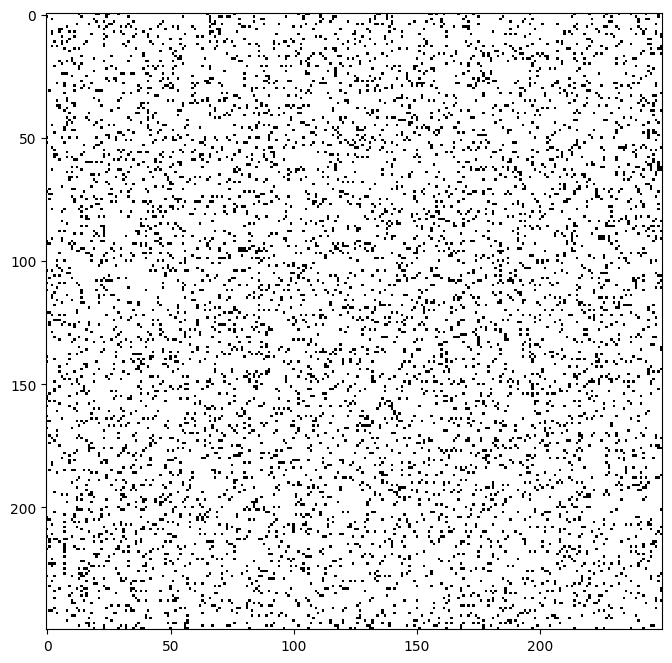

In [11]:
name = 'image1'
image1 = load(name)

plot_image(image1)

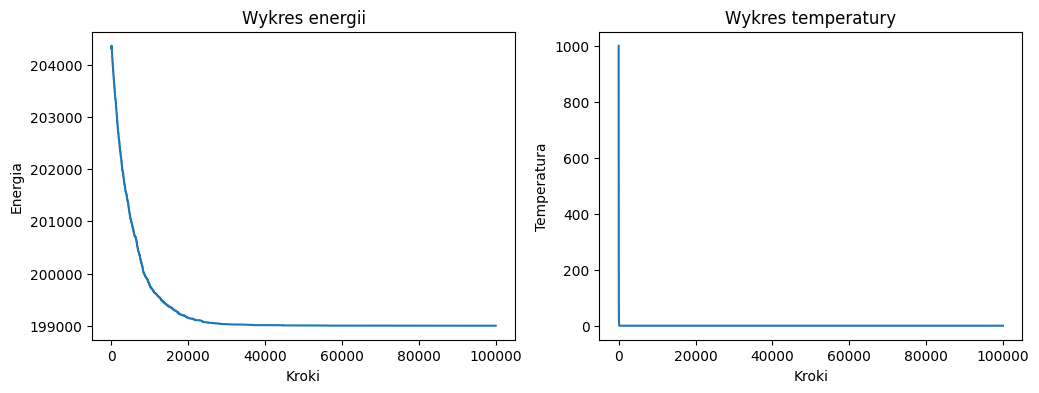

In [14]:
name = 'image1'
image1 = load(name)

cooling_function = exp_cooling
energy_function = n4_energy_plus
start_temperature = 1000
epochs = 100000

energy, temperature = simulated_annealing(image1, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

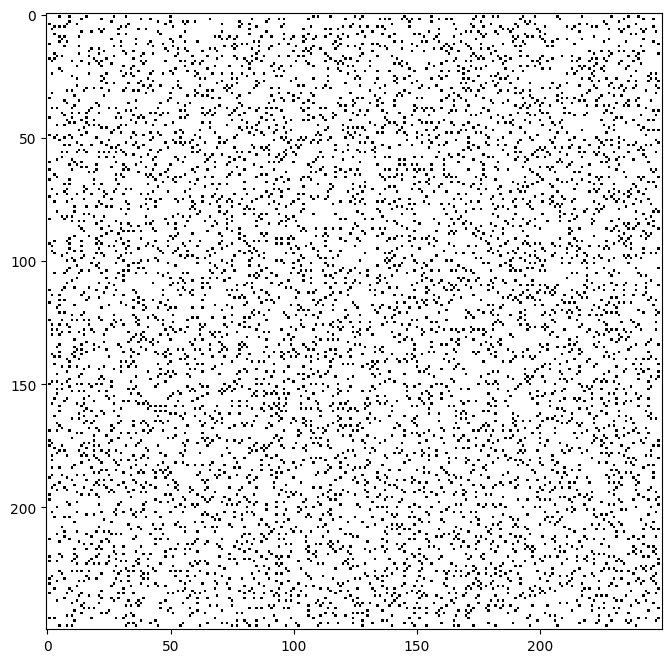

In [15]:
plot_image(image1)

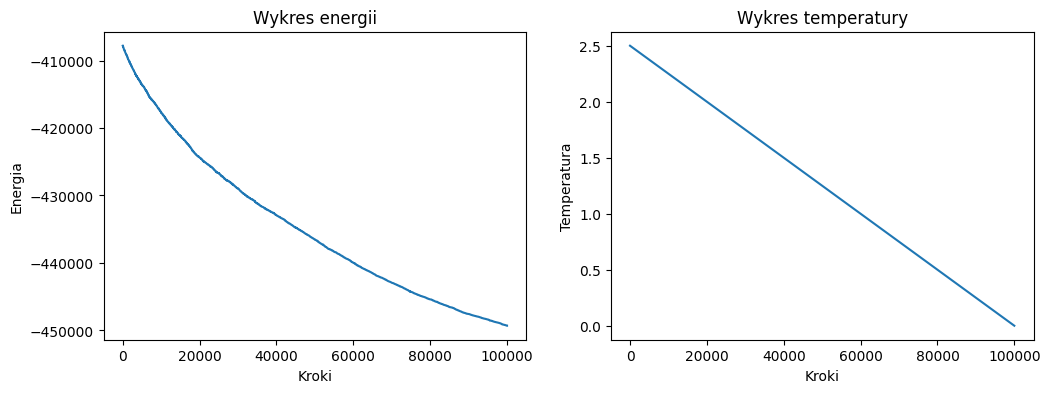

In [16]:
name = 'image1'
image1 = load(name)

cooling_function = lin_cooling
energy_function = n8_energy_minus
start_temperature = 2.5
epochs = 100000

energy, temperature = simulated_annealing(image1, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

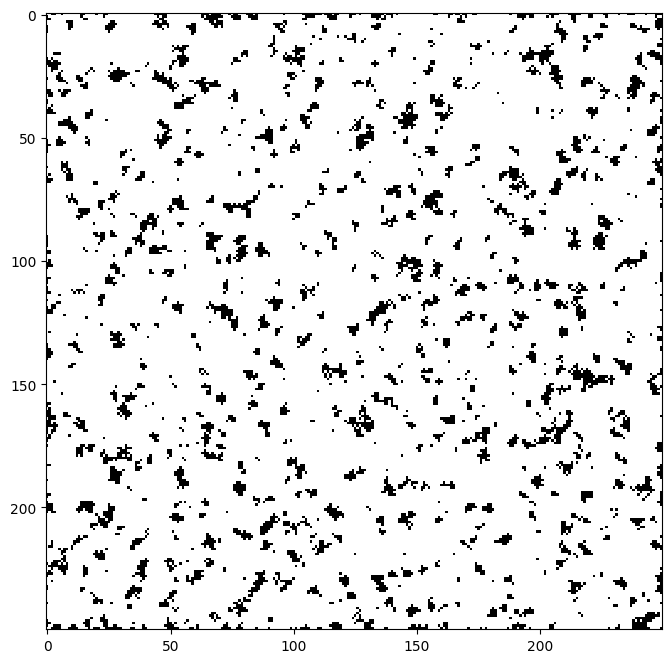

In [17]:
plot_image(image1)

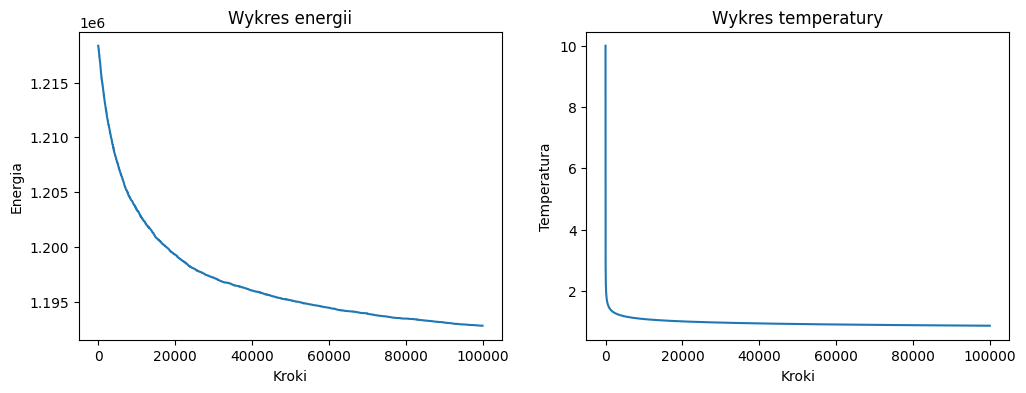

In [18]:
name = 'image1'
image1 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_plus
start_temperature = 10
epochs = 100000

energy, temperature = simulated_annealing(image1, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

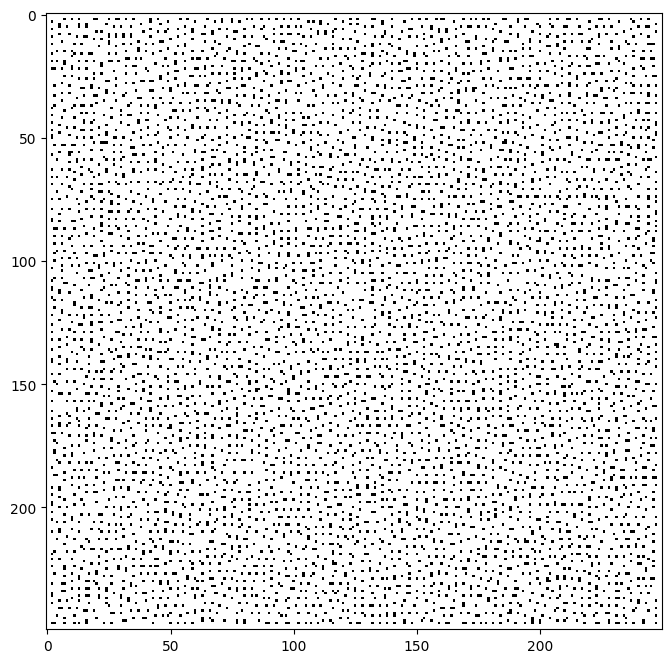

In [19]:
plot_image(image1)

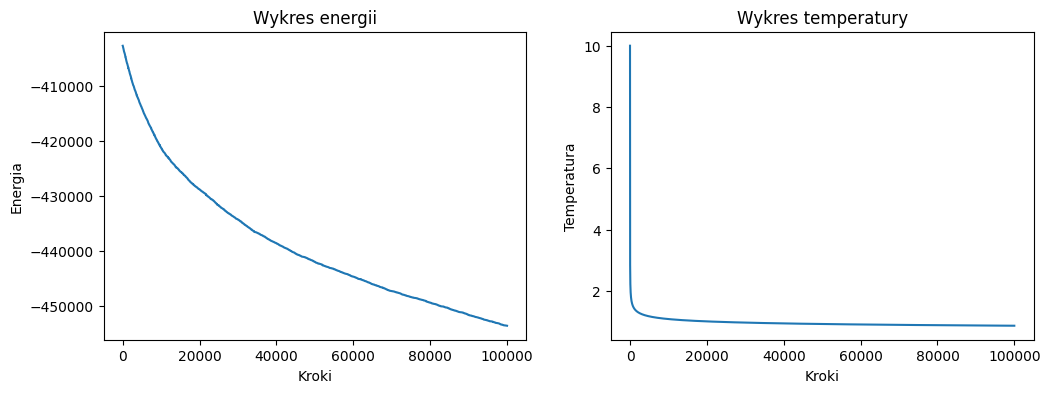

In [20]:
name = 'image1'
image1 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_plus_minus
start_temperature = 10
epochs = 100000

energy, temperature = simulated_annealing(image1, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

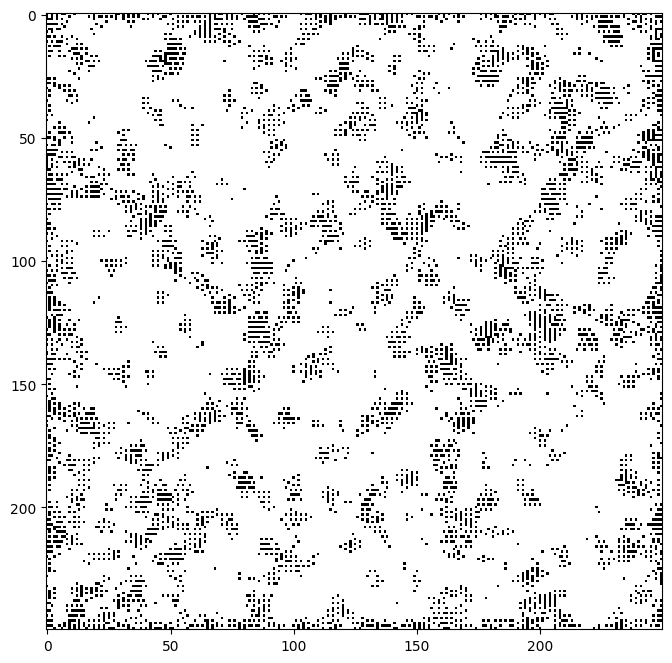

In [21]:
plot_image(image1)

#### Obraz 2 - 250x250 pixeli, gęstość czarnych punktów: 0.3

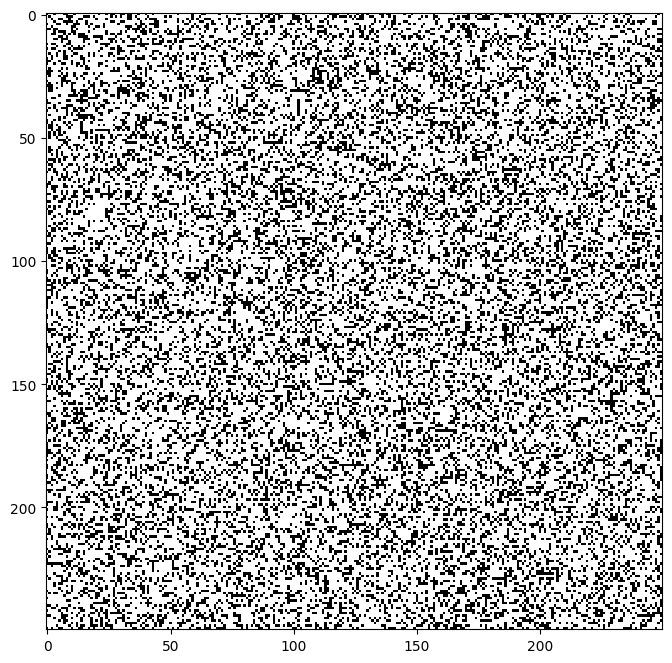

In [22]:
name = 'image3'
image3 = load(name)

plot_image(image3)

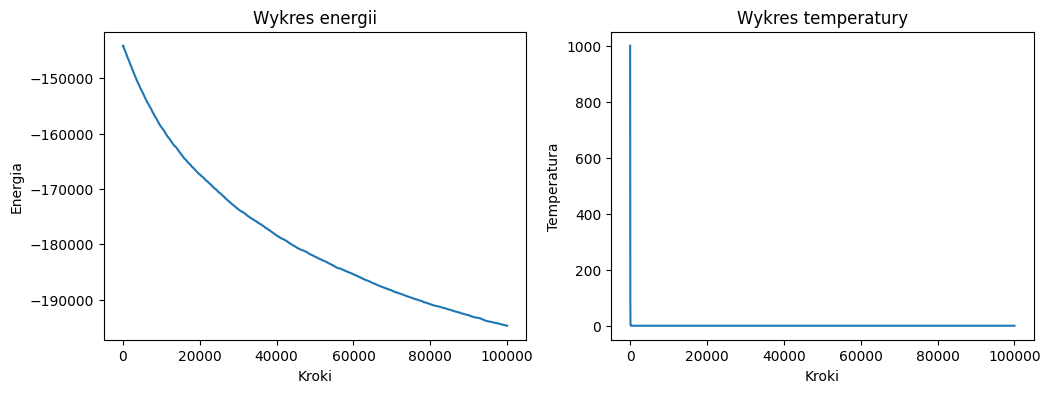

In [26]:
name = 'image3'
image3 = load(name)

cooling_function = exp_cooling
energy_function = n4_energy_minus
start_temperature = 1000
epochs = 100000

energy, temperature = simulated_annealing(image3, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

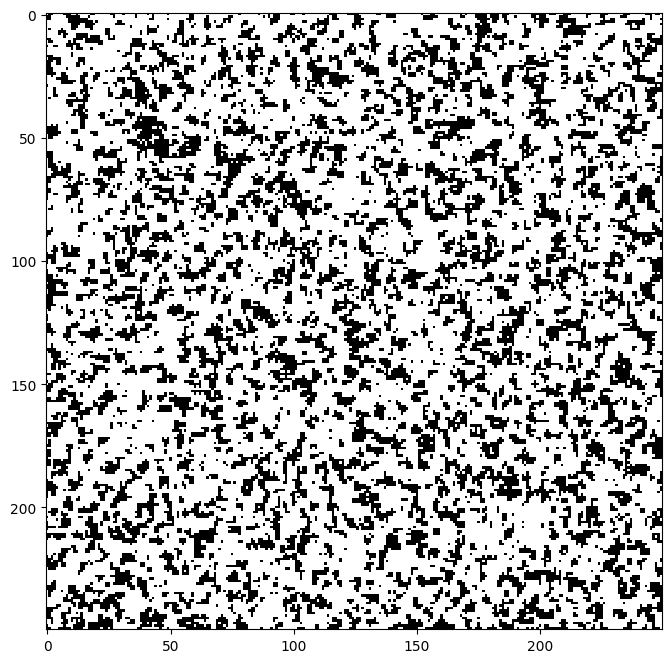

In [27]:
plot_image(image3)

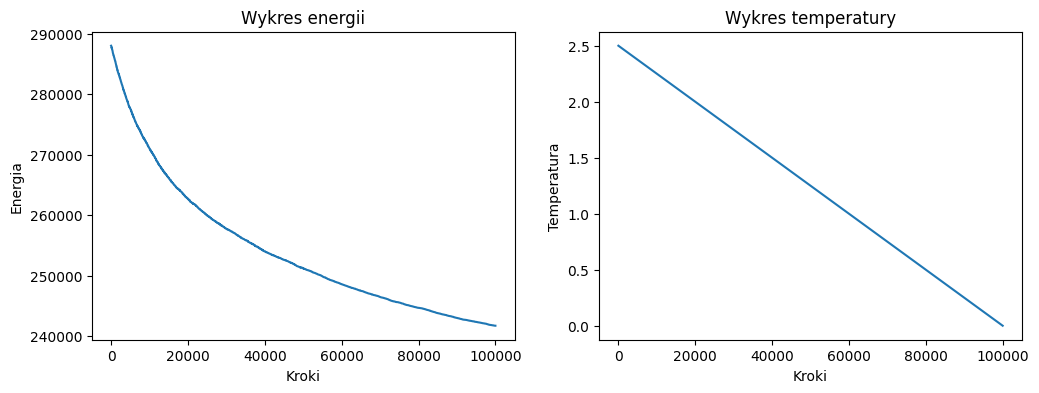

In [28]:
name = 'image3'
image3 = load(name)

cooling_function = lin_cooling
energy_function = n8_energy_plus
start_temperature = 2.5
epochs = 100000

energy, temperature = simulated_annealing(image3, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

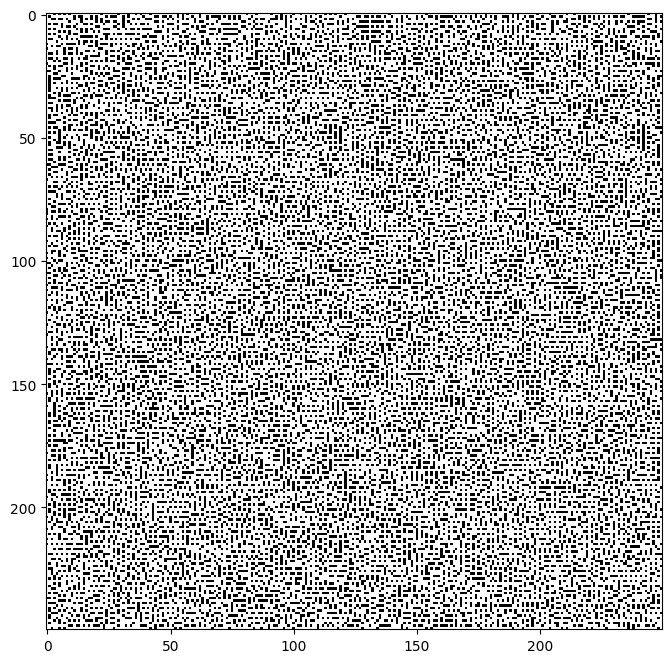

In [29]:
plot_image(image3)

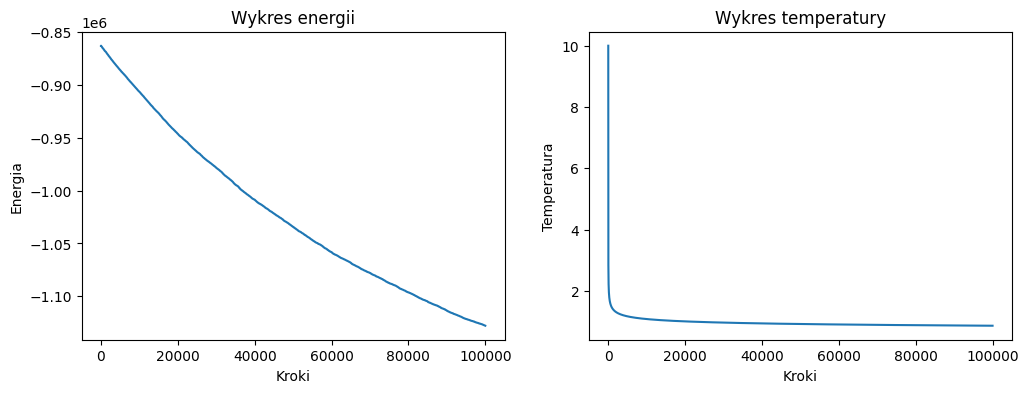

In [30]:
name = 'image3'
image3 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_minus
start_temperature = 10
epochs = 100000

energy, temperature = simulated_annealing(image3, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

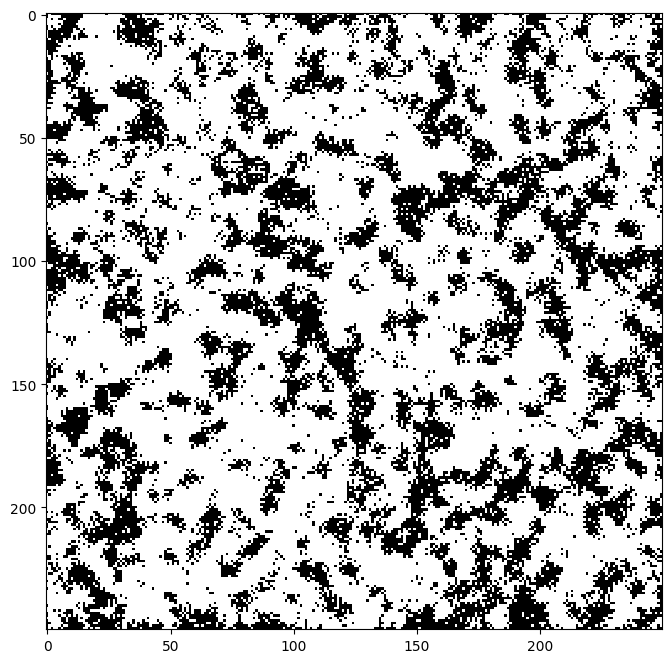

In [31]:
plot_image(image3)

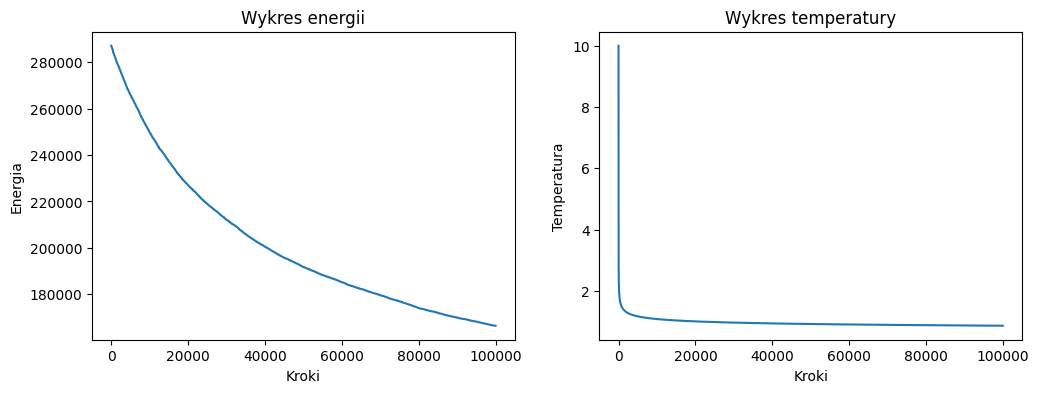

In [32]:
name = 'image3'
image3 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_minus_plus
start_temperature = 10
epochs = 100000

energy, temperature = simulated_annealing(image3, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

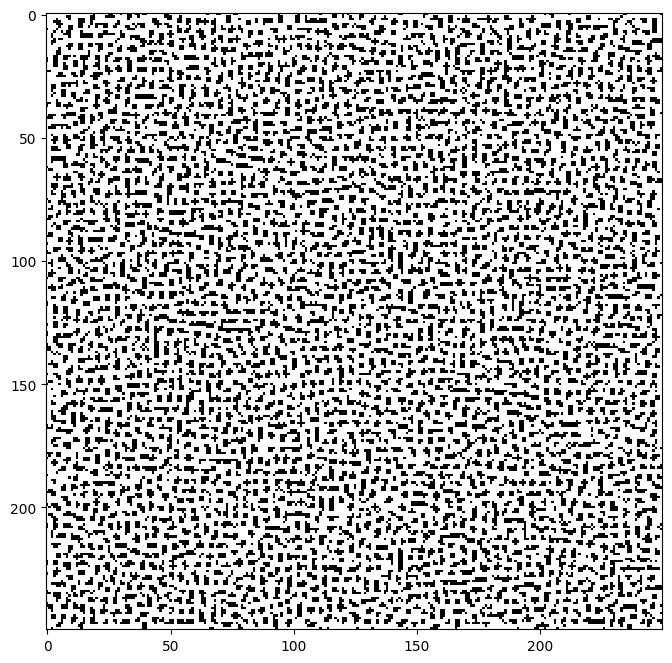

In [33]:
plot_image(image3)

#### Obraz 3 - 250x250 pixeli, gęstość czarnych punktów: 0.4

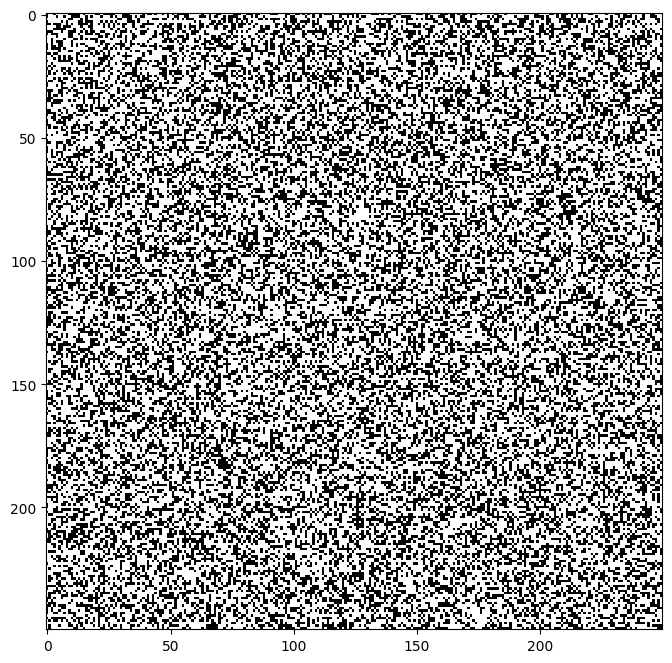

In [34]:
name = 'image5'
image5 = load(name)

plot_image(image5)

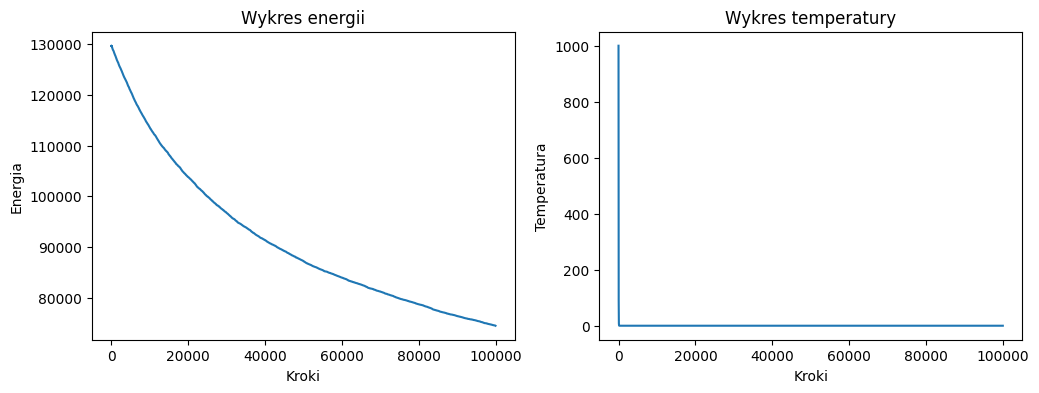

In [35]:
name = 'image5'
image5 = load(name)

cooling_function = exp_cooling
energy_function = n4_energy_plus
start_temperature = 1000
epochs = 100000

energy, temperature = simulated_annealing(image5, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

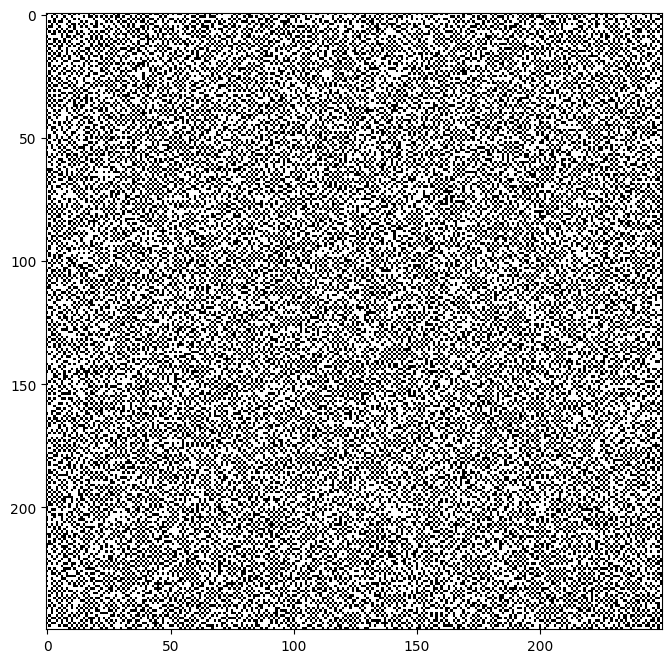

In [36]:
plot_image(image5)

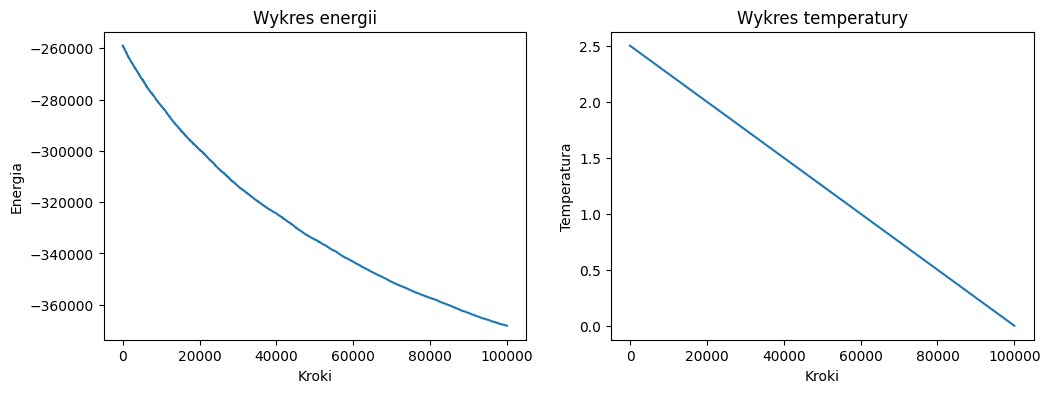

In [37]:
name = 'image5'
image5 = load(name)

cooling_function = lin_cooling
energy_function = n8_energy_minus
start_temperature = 2.5
epochs = 100000

energy, temperature = simulated_annealing(image5, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

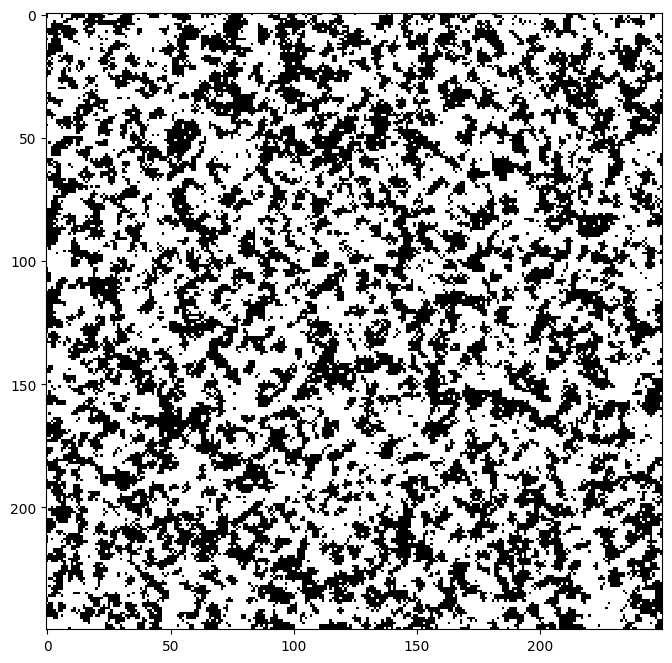

In [38]:
plot_image(image5)

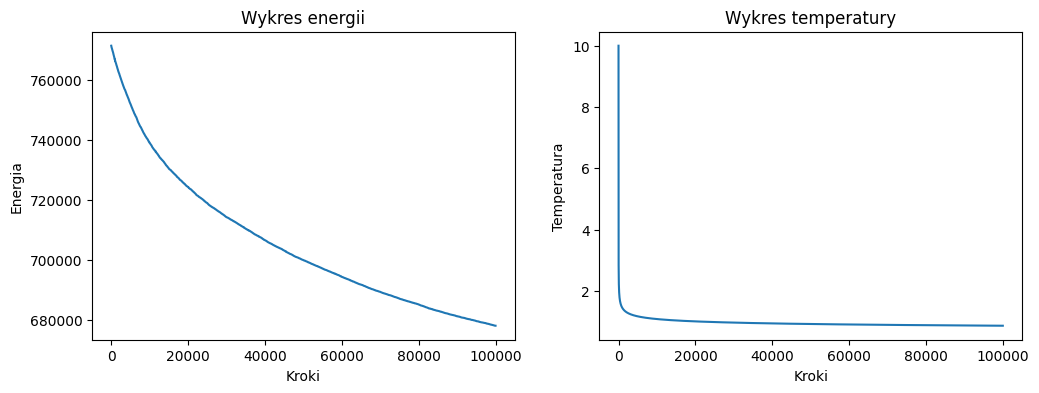

In [39]:
name = 'image5'
image5 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_plus
start_temperature = 10
epochs = 100000

energy, temperature = simulated_annealing(image5, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

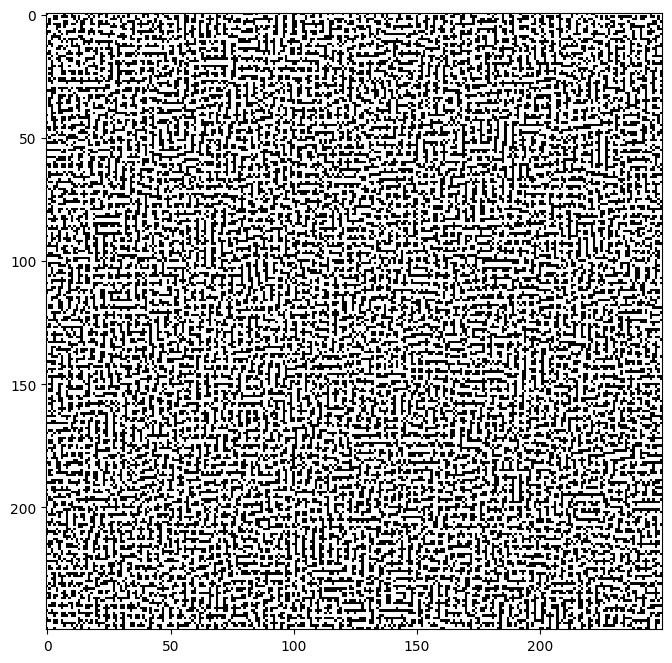

In [40]:
plot_image(image5)

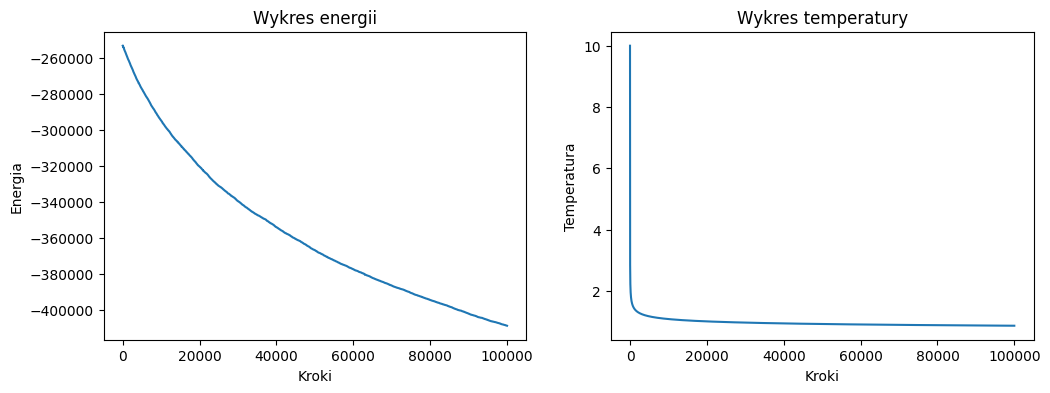

In [41]:
name = 'image5'
image5 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_plus_minus
start_temperature = 10
epochs = 100000

energy, temperature = simulated_annealing(image5, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

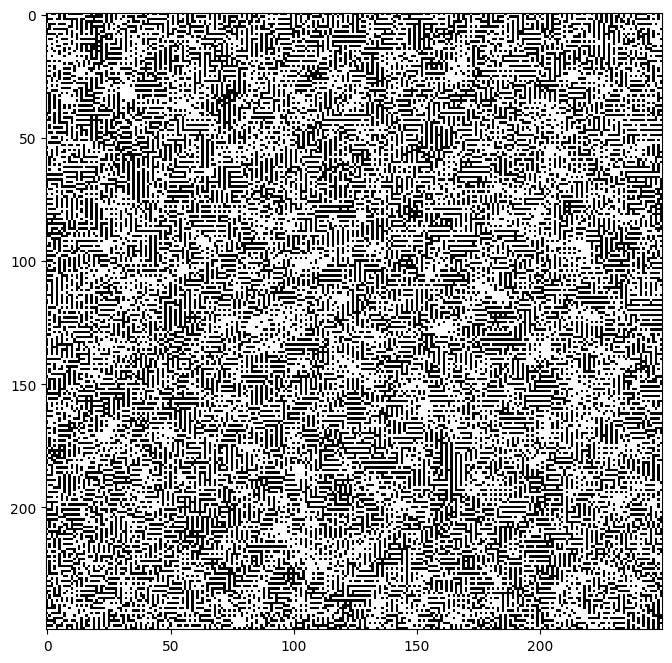

In [42]:
plot_image(image5)

### Ciekawsze funkcje na obrazach 1000x1000 pixeli

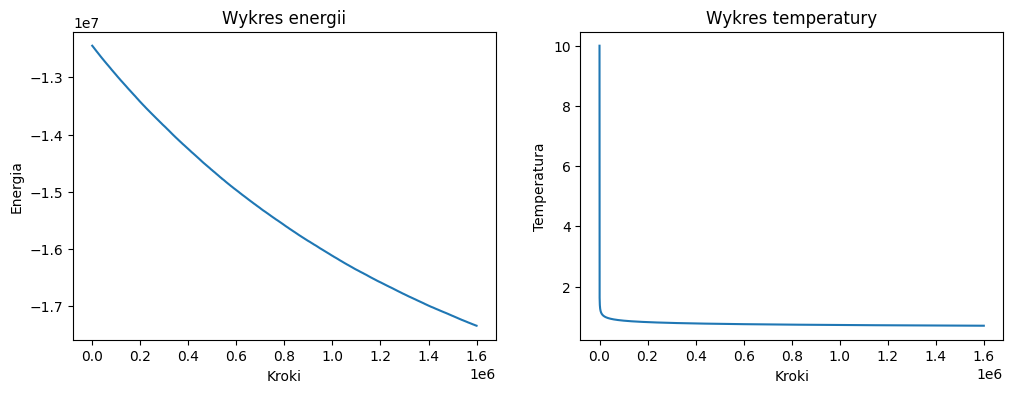

In [ ]:
name = 'image6'
image6 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_minus
start_temperature = 10
epochs = 1600000

energy, temperature = simulated_annealing(image6, epochs, start_temperature, energy_function, cooling_function)
plot_result(energy, temperature)

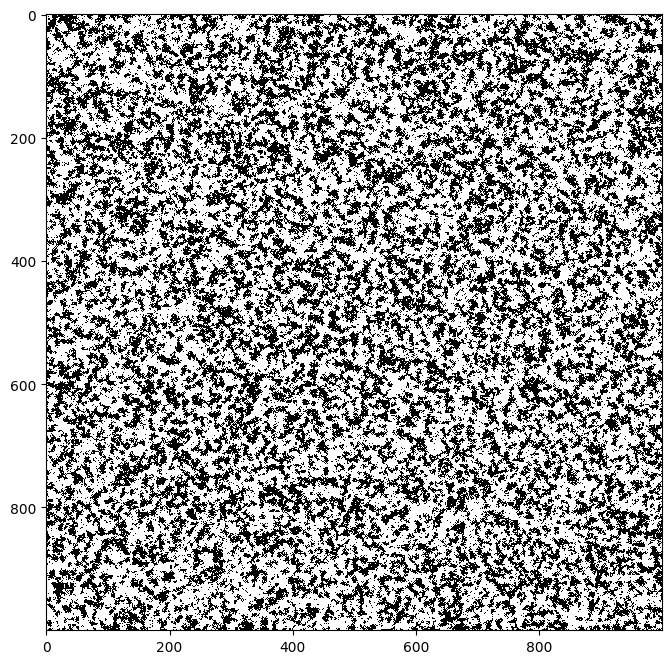

In [69]:
plot_image(image6)

In [73]:
name = 'image6'
image6 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_minus
start_temperature = 10
epochs = 1600000

energy, temperature = simulated_annealing_gif('n24_minus_image6', image6, epochs, start_temperature, energy_function, cooling_function)

In [77]:
display_image('n24_minus_image6.gif')

In [78]:
name = 'image6'
image6 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_plus
start_temperature = 10
epochs = 1600000

energy, temperature = simulated_annealing(image6, epochs, start_temperature, energy_function, cooling_function)

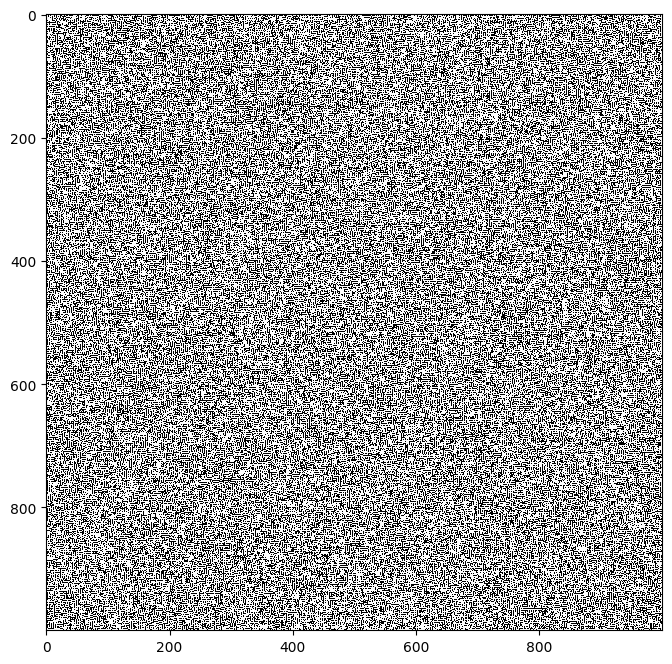

In [79]:
plot_image(image6)

In [80]:
name = 'image6'
image6 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_plus
start_temperature = 10
epochs = 1600000

energy, temperature = simulated_annealing_gif('n24_plus_image6', image6, epochs, start_temperature, energy_function, cooling_function)

In [82]:
display_image('n24_plus_image6.gif')

In [83]:
name = 'image6'
image6 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_minus_plus
start_temperature = 10
epochs = 1600000

energy, temperature = simulated_annealing(image6, epochs, start_temperature, energy_function, cooling_function)

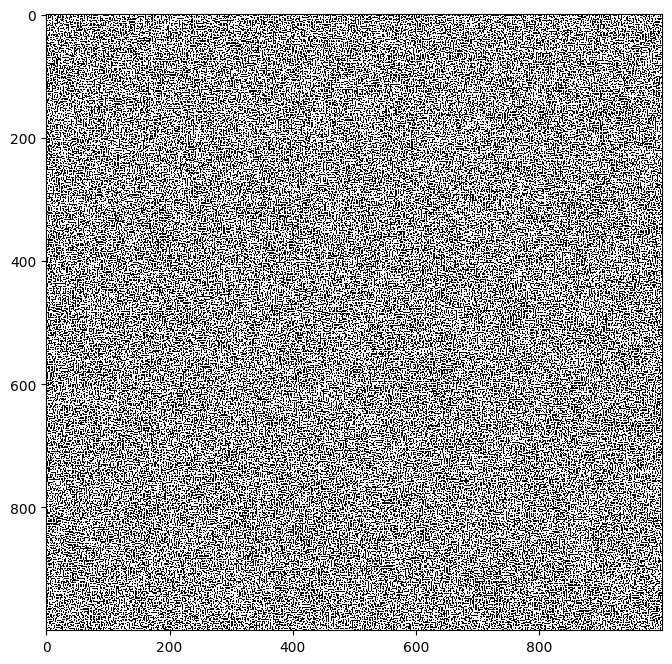

In [84]:
plot_image(image6)

In [85]:
name = 'image6'
image6 = load(name)

cooling_function = log_cooling
energy_function = n24_energy_minus_plus
start_temperature = 10
epochs = 1600000

energy, temperature = simulated_annealing_gif('n24_minus_plus_image6', image6, epochs, start_temperature, energy_function, cooling_function)

In [86]:
display_image('n24_minus_plus_image6.gif')